# 01 · Análisis exploratorio de datos

**Proyecto:** Alerta temprana de abandono de clientes (Telco Customer Churn)
**Curso:** Machine Learning · Maestría en Ciencia de Datos e Inteligencia Artificial · EPG UNAJ
**Docente:** Dr. Alain Paul Herrera Urtiaga
**Equipo:** Leydy Mayumy Coyllo Mamani · Noe Wilber Tipo Mamani · Jose Alfonso Nina Condori
**Producto:** 1

> **Pregunta del proyecto:** con los datos actuales de un cliente, ¿qué clientes cancelarán su servicio?

**Objetivo de este notebook:** conocer los datos, medir el abandono y encontrar de 3 a 5 hallazgos que orienten el modelado.

In [1]:
# Configuración común (el notebook es autocontenido: corre en local y en Google Colab)
import warnings
warnings.filterwarnings("ignore")
import importlib, subprocess, sys
for _paquete in ["scipy"]:
    try:
        importlib.import_module(_paquete)
    except ImportError:  # en Colab puede faltar alguna librería
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _paquete], check=True)

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
URL_CSV = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
RUTA_LOCAL = Path("../data/Telco-Customer-Churn.csv")
EN_REPO = RUTA_LOCAL.exists()
RES = Path("../resultados") if EN_REPO else Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta: azul = no abandona, naranja = abandona
AZUL, NARANJA, AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def guardar_figura(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")

def guardar_json(obj, nombre):
    (RES / nombre).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

print("Datos locales:" if EN_REPO else "Datos desde la URL pública:", RUTA_LOCAL if EN_REPO else URL_CSV)

Datos locales: ../data/Telco-Customer-Churn.csv


In [2]:
# Carga y traducción al español (misma lógica que src/churn/datos.py)
MAPEO_COLUMNAS = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "adulto_mayor",
    "Partner": "tiene_pareja",
    "Dependents": "tiene_dependientes",
    "tenure": "antiguedad_meses",
    "PhoneService": "servicio_telefonico",
    "MultipleLines": "lineas_multiples",
    "InternetService": "servicio_internet",
    "OnlineSecurity": "seguridad_en_linea",
    "OnlineBackup": "respaldo_en_linea",
    "DeviceProtection": "proteccion_dispositivo",
    "TechSupport": "soporte_tecnico",
    "StreamingTV": "tv_streaming",
    "StreamingMovies": "peliculas_streaming",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "factura_electronica",
    "PaymentMethod": "metodo_pago",
    "MonthlyCharges": "cargo_mensual",
    "TotalCharges": "cargo_total",
    "Churn": "abandona",
}

MAPEO_VALORES = {
    "Yes": "Sí",
    "No": "No",
    "No internet service": "Sin internet",
    "No phone service": "Sin teléfono",
    "Month-to-month": "Mensual",
    "One year": "Un año",
    "Two year": "Dos años",
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "Electronic check": "Cheque electrónico",
    "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia bancaria (automática)",
    "Credit card (automatic)": "Tarjeta de crédito (automática)",
    "Male": "Hombre",
    "Female": "Mujer",
}

OBJETIVO = "abandona"
ID = "id_cliente"
NUMERICAS = ["antiguedad_meses", "cargo_mensual"]
CATEGORICAS = [
    "genero", "adulto_mayor", "tiene_pareja", "tiene_dependientes",
    "servicio_telefonico", "lineas_multiples", "servicio_internet",
    "seguridad_en_linea", "respaldo_en_linea", "proteccion_dispositivo",
    "soporte_tecnico", "tv_streaming", "peliculas_streaming",
    "tipo_contrato", "factura_electronica", "metodo_pago",
]
# cargo_total se excluye del modelo por redundancia (≈ antigüedad × cargo mensual).
# La evidencia está en notebooks/02_modelos.ipynb y en DECISIONES.md.
EXCLUIDAS = [ID, "cargo_total"]
VARIABLES_MODELO = NUMERICAS + CATEGORICAS


def traducir(df: pd.DataFrame) -> pd.DataFrame:
    """Renombra columnas y traduce categorías. Acepta columnas en inglés o ya en español.

    No imputa: los blancos de ``cargo_total`` quedan como NaN.
    """
    df = df.rename(columns=MAPEO_COLUMNAS).copy()
    for col in df.columns:
        if col in (ID, OBJETIVO, "cargo_total") or col in NUMERICAS:
            continue
        if col == "adulto_mayor":
            df[col] = df[col].map(
                lambda v: "Sí" if str(v).strip() in ("1", "1.0", "Sí", "Si", "Yes")
                else ("No" if str(v).strip() in ("0", "0.0", "No") else np.nan)
            )
            continue
        if df[col].dtype == object or pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].map(lambda v: MAPEO_VALORES.get(v, v) if isinstance(v, str) else v)
            if col == "servicio_internet":  # en esta columna "No" significa "sin internet"
                df[col] = df[col].replace({"No": "Sin internet"})
    if "cargo_total" in df.columns:
        df["cargo_total"] = pd.to_numeric(
            df["cargo_total"].astype(str).str.strip().replace("", np.nan), errors="coerce"
        )
    for col in NUMERICAS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if OBJETIVO in df.columns and not pd.api.types.is_numeric_dtype(df[OBJETIVO]):
        df[OBJETIVO] = df[OBJETIVO].map({"Yes": 1, "No": 0, "Sí": 1}).astype(int)
    return df


def separar_X_y(df: pd.DataFrame):
    """Devuelve (X, y) con solo las variables que usa el modelo."""
    return df[VARIABLES_MODELO].copy(), df[OBJETIVO].astype(int).copy()

df_crudo = pd.read_csv(RUTA_LOCAL) if EN_REPO else pd.read_csv(URL_CSV)
df = traducir(df_crudo)
print(df.shape)

(7043, 21)


## 1. Tamaño, tipos y valores faltantes

In [3]:
tipos = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(),
                      "valores_distintos": df.nunique()})
blancos_crudo = int((df_crudo["TotalCharges"].astype(str).str.strip() == "").sum())
resumen = {
    "filas": int(df.shape[0]), "columnas": int(df.shape[1]),
    "faltantes_cargo_total": int(df["cargo_total"].isna().sum()),
    "blancos_TotalCharges_en_crudo": blancos_crudo,
    "antiguedad_de_los_faltantes": sorted(df.loc[df["cargo_total"].isna(), "antiguedad_meses"].unique().tolist()),
    "ids_duplicados": int(df["id_cliente"].duplicated().sum()),
    "filas_duplicadas_sin_id": int(df.drop(columns="id_cliente").duplicated().sum()),
}
print(json.dumps(resumen, indent=2, ensure_ascii=False))
tipos

{
  "filas": 7043,
  "columnas": 21,
  "faltantes_cargo_total": 11,
  "blancos_TotalCharges_en_crudo": 11,
  "antiguedad_de_los_faltantes": [
    0
  ],
  "ids_duplicados": 0,
  "filas_duplicadas_sin_id": 22
}


,tipo,faltantes,valores_distintos
id_cliente,str,0,7043
genero,str,0,2
adulto_mayor,str,0,2
tiene_pareja,str,0,2
tiene_dependientes,str,0,2
antiguedad_meses,int64,0,73
servicio_telefonico,str,0,2
lineas_multiples,str,0,3
servicio_internet,str,0,3
seguridad_en_linea,str,0,3


**Lectura.** El dataset tiene **7 043 clientes y 21 columnas**. Solo hay **11 valores faltantes**, todos en `cargo_total`: venían como texto en blanco y corresponden a clientes con **0 meses de antigüedad** (aún no se les había facturado). No hay identificadores repetidos; hay 22 filas idénticas si se ignora el `id_cliente`, pero son clientes distintos con el mismo perfil, así que se conservan. La imputación de los 11 blancos se hace dentro del Pipeline, no aquí.

## 2. Proporción de abandono

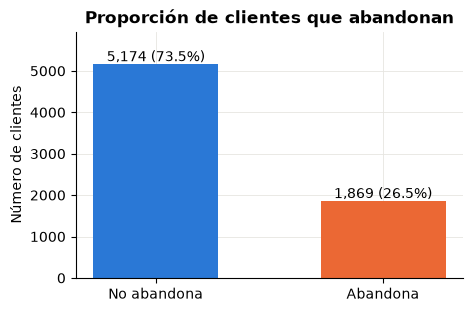

Tasa de abandono: 26.54%


In [4]:
conteo = df["abandona"].value_counts().sort_index()
tasa = df["abandona"].mean()
resumen.update({"n_abandona": int(conteo[1]), "n_no_abandona": int(conteo[0]), "tasa_abandono": round(float(tasa), 4)})
guardar_json(resumen, "01_resumen_datos.json")

fig, ax = plt.subplots(figsize=(5, 3.2))
barras = ax.bar(["No abandona", "Abandona"], conteo.values, color=[AZUL, NARANJA], width=0.55)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,} ({v / len(df):.1%})", ha="center")
ax.set_title("Proporción de clientes que abandonan")
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, conteo.max() * 1.15)
guardar_figura(fig, "01_proporcion_abandono.png"); plt.show()
print(f"Tasa de abandono: {tasa:.2%}")

**Lectura.** **1 869 de 7 043 clientes abandonaron (26.5 %)**. La clase de interés es minoritaria (aprox. 1 de cada 4): un modelo que dijera "nadie abandona" acertaría el 73.5 % de las veces y no serviría para nada. Por eso no usamos la exactitud (*accuracy*) como métrica, la división train/test es **estratificada** y los modelos tratan el desbalance.

## 3. ¿Qué variables se asocian más con el abandono?

Para elegir los hallazgos con evidencia (y no por intuición) medimos la asociación de cada variable categórica con el abandono usando la **V de Cramér** (0 = sin asociación, 1 = asociación perfecta).

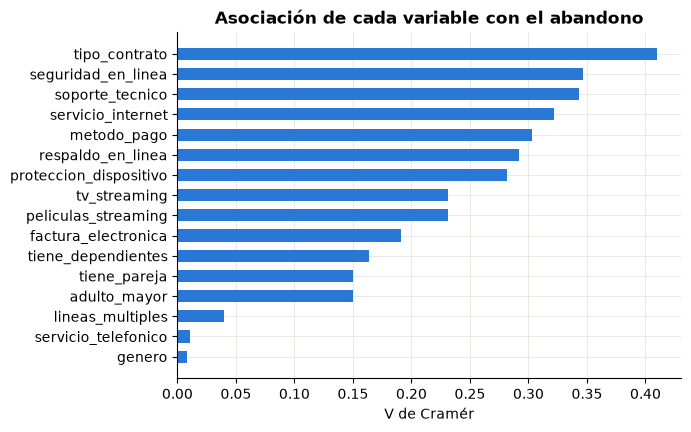

,variable,v_cramer
13,tipo_contrato,0.410
7,seguridad_en_linea,0.347
10,soporte_tecnico,0.343
6,servicio_internet,0.322
15,metodo_pago,0.303
8,respaldo_en_linea,0.292
9,proteccion_dispositivo,0.282
12,peliculas_streaming,0.231
11,tv_streaming,0.231
14,factura_electronica,0.191


In [5]:
from scipy.stats import chi2_contingency

def v_cramer(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla)[0]
    return float(np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))))

asociacion = (pd.DataFrame({"variable": CATEGORICAS,
                            "v_cramer": [v_cramer(df[v], df["abandona"]) for v in CATEGORICAS]})
              .sort_values("v_cramer", ascending=False).round(3))
asociacion.to_csv(RES / "01_asociacion_variables.csv", index=False)

tasas = []
for v in CATEGORICAS:
    g = df.groupby(v)["abandona"].agg(n="size", tasa_abandono="mean").reset_index()
    g.insert(0, "variable", v); g = g.rename(columns={v: "categoria"})
    tasas.append(g)
tasas = pd.concat(tasas).round(4)
tasas.to_csv(RES / "01_tasas_por_categoria.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
a = asociacion.sort_values("v_cramer")
ax.barh(a["variable"], a["v_cramer"], color=AZUL, height=0.6)
ax.set_title("Asociación de cada variable con el abandono")
ax.set_xlabel("V de Cramér"); ax.set_ylabel("")
guardar_figura(fig, "01_asociacion_variables.png"); plt.show()
asociacion

**Lectura.** La variable más asociada con el abandono es el **tipo de contrato** (V = 0.41), seguida de los servicios de protección (**seguridad en línea** 0.35 y **soporte técnico** 0.34), el **servicio de internet** (0.32) y el **método de pago** (0.30). En el otro extremo, el **género** prácticamente no tiene relación con el abandono (V = 0.008). Los hallazgos siguientes siguen este orden, más la antigüedad (numérica).

## 4. Hallazgos

### Hallazgo 1 · Tipo de contrato

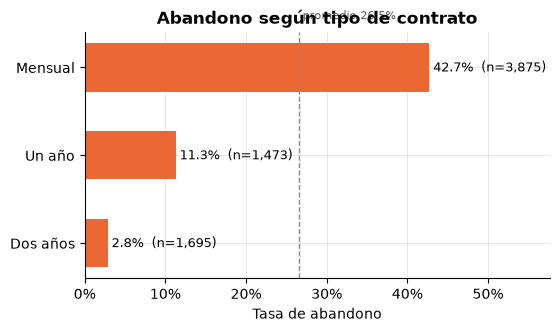

,n,tasa
tipo_contrato,,
Mensual,3875,0.4271
Un año,1473,0.1127
Dos años,1695,0.0283


In [6]:
g = df.groupby("tipo_contrato")["abandona"].agg(n="size", tasa="mean")
g = g.loc[['Mensual', 'Un año', 'Dos años']]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(g.index[::-1], g["tasa"][::-1], color=NARANJA, height=0.55)
ax.axvline(tasa, color=GRIS, ls="--", lw=1)
ax.text(tasa, len(g) - 0.45, f" promedio {tasa:.1%}", color="#52514e", fontsize=8)
for i, (t, n) in enumerate(zip(g["tasa"][::-1], g["n"][::-1])):
    ax.text(t + 0.005, i, f"{t:.1%}  (n={n:,})", va="center", fontsize=9)
ax.set_title("Abandono según tipo de contrato"); ax.set_xlabel("Tasa de abandono"); ax.set_xlim(0, max(g["tasa"]) * 1.35)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
guardar_figura(fig, "01_h1_contrato.png"); plt.show()
g.round(4)

**Hallazgo 1.** Los clientes con **contrato mensual abandonan el 42.7 %** de las veces, frente al **11.3 %** con contrato de un año y apenas el **2.8 %** con contrato de dos años: quince veces menos. El contrato mensual es además el más común (3 875 clientes, 55 %). *Implicación:* el tipo de contrato será una variable central y sugiere una acción concreta: ofrecer migrar a contratos más largos.

### Hallazgo 2 · Antigüedad del cliente

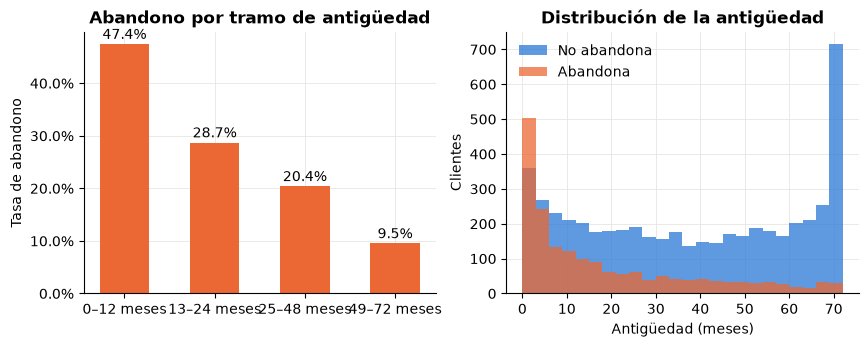

,n,tasa
antiguedad_meses,,
0–12 meses,2186,0.4744
13–24 meses,1024,0.2871
25–48 meses,1594,0.2039
49–72 meses,2239,0.0951


,antiguedad_meses,cargo_mensual
abandona,,
0,38.0,64.425
1,10.0,79.650


In [7]:
tramos = pd.cut(df["antiguedad_meses"], [-1, 12, 24, 48, 72],
                labels=["0–12 meses", "13–24 meses", "25–48 meses", "49–72 meses"])
g = df.groupby(tramos, observed=True)["abandona"].agg(n="size", tasa="mean")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].bar(g.index.astype(str), g["tasa"], color=NARANJA, width=0.55)
for i, t in enumerate(g["tasa"]):
    axs[0].text(i, t + 0.01, f"{t:.1%}", ha="center")
axs[0].set_title("Abandono por tramo de antigüedad"); axs[0].set_ylabel("Tasa de abandono")
axs[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
bins = np.arange(0, 75, 3)
axs[1].hist(df.loc[df.abandona == 0, "antiguedad_meses"], bins=bins, color=AZUL, alpha=0.75, label="No abandona")
axs[1].hist(df.loc[df.abandona == 1, "antiguedad_meses"], bins=bins, color=NARANJA, alpha=0.75, label="Abandona")
axs[1].set_title("Distribución de la antigüedad"); axs[1].set_xlabel("Antigüedad (meses)"); axs[1].set_ylabel("Clientes")
axs[1].legend(frameon=False)
guardar_figura(fig, "01_h2_antiguedad.png"); plt.show()
medianas = df.groupby("abandona")[["antiguedad_meses", "cargo_mensual"]].median()
g.to_csv(RES / "01_tasa_por_antiguedad.csv")
medianas.to_csv(RES / "01_medianas_por_clase.csv")
display(g.round(4)); medianas

**Hallazgo 2.** El riesgo se concentra en los **primeros meses**: en el primer año abandona el **47.4 %** de los clientes, y la tasa baja de forma sostenida hasta el **9.5 %** entre quienes llevan de 49 a 72 meses. La mediana de antigüedad es de **10 meses** entre quienes abandonan y de **38 meses** entre quienes se quedan. *Implicación:* la antigüedad es una variable numérica clave y el periodo inicial es donde más vale actuar.

### Hallazgo 3 · Servicio de internet y cargo mensual

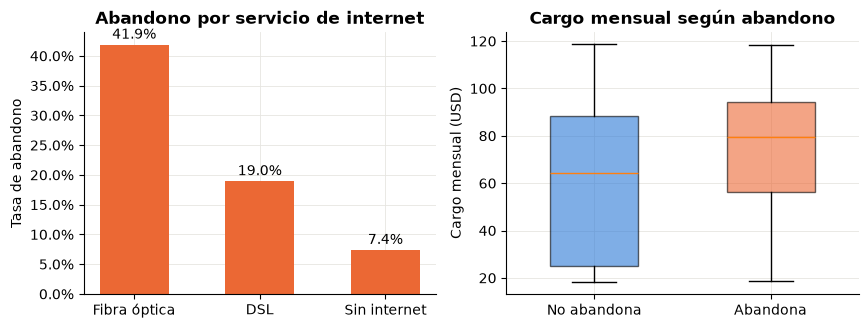

,n,tasa
servicio_internet,,
Fibra óptica,3096,0.4189
DSL,2421,0.1896
Sin internet,1526,0.0740


servicio_internet
DSL             56.150
Fibra óptica    91.675
Sin internet    20.150
Name: cargo_mensual, dtype: float64

In [8]:
g = df.groupby("servicio_internet")["abandona"].agg(n="size", tasa="mean").sort_values("tasa", ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].bar(g.index, g["tasa"], color=NARANJA, width=0.55)
for i, t in enumerate(g["tasa"]):
    axs[0].text(i, t + 0.01, f"{t:.1%}", ha="center")
axs[0].set_title("Abandono por servicio de internet"); axs[0].set_ylabel("Tasa de abandono")
axs[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
datos_caja = [df.loc[df.abandona == k, "cargo_mensual"] for k in (0, 1)]
caja = axs[1].boxplot(datos_caja, tick_labels=["No abandona", "Abandona"], patch_artist=True, widths=0.5)
for parche, color in zip(caja["boxes"], [AZUL, NARANJA]):
    parche.set_facecolor(color); parche.set_alpha(0.6)
axs[1].set_title("Cargo mensual según abandono"); axs[1].set_ylabel("Cargo mensual (USD)")
guardar_figura(fig, "01_h3_internet_cargo.png"); plt.show()
cargo_fibra = df.groupby("servicio_internet")["cargo_mensual"].median()
display(g.round(4)); cargo_fibra

**Hallazgo 3.** Los clientes con **fibra óptica abandonan el 41.9 %**, más del doble que con DSL (19.0 %), y los clientes sin internet apenas el 7.4 %. Quienes abandonan pagan más: su cargo mensual mediano es **79.65 USD** frente a **64.43 USD** de quienes se quedan. *Implicación:* el servicio de fibra (caro) parece no cumplir expectativas o tiene más competencia; el modelo debe combinar tipo de servicio y cargo mensual.

### Hallazgo 4 · Método de pago

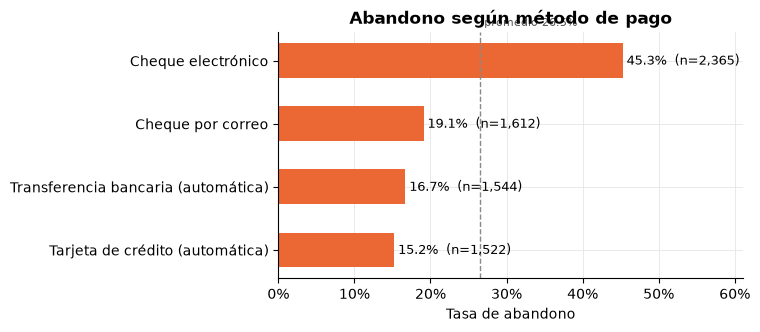

,n,tasa
metodo_pago,,
Cheque electrónico,2365,0.4529
Cheque por correo,1612,0.1911
Transferencia bancaria (automática),1544,0.1671
Tarjeta de crédito (automática),1522,0.1524


In [9]:
g = df.groupby("metodo_pago")["abandona"].agg(n="size", tasa="mean")
g = g.sort_values('tasa', ascending=False)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(g.index[::-1], g["tasa"][::-1], color=NARANJA, height=0.55)
ax.axvline(tasa, color=GRIS, ls="--", lw=1)
ax.text(tasa, len(g) - 0.45, f" promedio {tasa:.1%}", color="#52514e", fontsize=8)
for i, (t, n) in enumerate(zip(g["tasa"][::-1], g["n"][::-1])):
    ax.text(t + 0.005, i, f"{t:.1%}  (n={n:,})", va="center", fontsize=9)
ax.set_title("Abandono según método de pago"); ax.set_xlabel("Tasa de abandono"); ax.set_xlim(0, max(g["tasa"]) * 1.35)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
guardar_figura(fig, "01_h4_metodo_pago.png"); plt.show()
g.round(4)

**Hallazgo 4.** Quienes pagan con **cheque electrónico abandonan el 45.3 %**, frente a 15–19 % con los otros tres métodos (los dos automáticos son los más bajos: 15.2 % tarjeta y 16.7 % transferencia). *Implicación:* el método de pago es una señal de compromiso; los pagos automáticos se asocian a clientes más estables. Ojo: es asociación, no causa.

### Hallazgo 5 · Servicios de protección (soporte técnico y seguridad en línea)

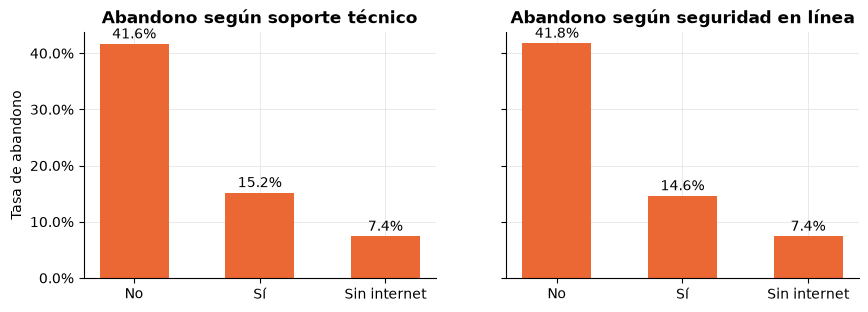

n    tasa
                   soporte_tecnico              
soporte_tecnico    No               3473  0.4164
                   Sí               2044  0.1517
                   Sin internet     1526  0.0740
seguridad_en_linea No               3498  0.4177
                   Sí               2019  0.1461
                   Sin internet     1526  0.0740

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
tablas = {}
for ax, v, titulo in zip(axs, ["soporte_tecnico", "seguridad_en_linea"], ["Soporte técnico", "Seguridad en línea"]):
    g = df.groupby(v)["abandona"].agg(n="size", tasa="mean").loc[["No", "Sí", "Sin internet"]]
    tablas[v] = g
    ax.bar(g.index, g["tasa"], color=NARANJA, width=0.55)
    for i, t in enumerate(g["tasa"]):
        ax.text(i, t + 0.01, f"{t:.1%}", ha="center")
    ax.set_title(f"Abandono según {titulo.lower()}")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axs[0].set_ylabel("Tasa de abandono")
guardar_figura(fig, "01_h5_proteccion.png"); plt.show()
pd.concat(tablas).round(4)

**Hallazgo 5.** Sin **soporte técnico** abandona el **41.6 %**, con soporte el **15.2 %**; sin **seguridad en línea** el **41.8 %**, con ella el **14.6 %**. *Implicación:* los servicios de protección se asocian a clientes más fieles; son candidatos naturales para una oferta de retención (por ejemplo, regalarlos unos meses).

## 5. Variable `cargo_total`: ¿aporta o es redundante?

In [11]:
d = df.dropna(subset=["cargo_total"])
aprox = d["antiguedad_meses"] * d["cargo_mensual"]
corr = float(np.corrcoef(d["cargo_total"], aprox)[0, 1])
print(f"Correlación entre cargo_total y antigüedad × cargo mensual: {corr:.4f}")
guardar_json({"correlacion_cargo_total_vs_producto": round(corr, 4)}, "01_cargo_total.json")

Correlación entre cargo_total y antigüedad × cargo mensual: 0.9996


**Lectura.** `cargo_total` tiene una correlación de **0.9996** con `antiguedad_meses × cargo_mensual`: es prácticamente una combinación de dos variables que ya tenemos. No es fuga de datos en sentido estricto (se conoce en el momento de predecir), pero es **redundante**. En el notebook 02 comprobamos si aporta algo al modelo antes de decidir.

## Hallazgos principales

1. **El abandono es minoritario (26.5 %)**: hay que usar métricas adecuadas al desbalance (recall, PR-AUC) y estratificar.
2. **El contrato mensual es la señal más fuerte** (42.7 % de abandono frente a 2.8 % en contratos de dos años).
3. **Los clientes nuevos se van más**: 47.4 % en el primer año frente a 9.5 % después de cuatro años.
4. **Fibra óptica y cheque electrónico** concentran el riesgo (41.9 % y 45.3 %), junto con cargos mensuales más altos.
5. **Los servicios de protección** (soporte técnico, seguridad en línea) se asocian a menos de la mitad de abandono.

**Para el modelado:** usaremos todas las variables salvo `id_cliente` y, previsiblemente, `cargo_total` (redundante, r = 0.9996); el género casi no se asocia con el abandono, pero lo mantenemos para poder revisar sesgos en el notebook 05.